# Observatorio de la Sanidad en Castilla y León
## Análisis exploratorio de las listas de espera (2018-2026)

**Autor:** Diego Trascasa García · **Datos:** Sacyl (Portal de Salud de la Junta de Castilla y León) e INE

Este cuaderno se lee como un informe. Responde a cinco preguntas sobre la lista de espera
**quirúrgica** de los 14 hospitales públicos de Castilla y León y añade una mirada a las
**consultas externas** y una **previsión** a 12 meses.

**Cómo leer las cifras**

- Cada dato es una *foto* de la lista de espera el último día de cada trimestre (31 de marzo, 30 de junio, 30 de septiembre y 31 de diciembre).
- La cifra principal son los **pacientes en espera estructural**, la que usa oficialmente el Sistema Nacional de Salud (Real Decreto 605/2003). Son los que esperan por causas atribuibles al sistema sanitario. No incluyen a quien aplazó la operación por motivos personales o clínicos, ni a quien rechazó operarse en otro centro.
- La **demora media** son los días que, de media, llevan esperando esos pacientes en la fecha del corte.

Todos los datos salen de la base de datos `data/sanidad_cyl.db`, que genera `python ejecutar_todo.py`.

In [1]:
import sqlite3
import sys
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# Los módulos del proyecto están en src/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import estilo  # plantilla visual común (colores y tipografía)
from estilo import CONTEXTO, DESTACADO, PRINCIPAL, TERCERO

# Gráficos interactivos en Jupyter y, además, una imagen estática para que se vean en GitHub
pio.renderers.default = "plotly_mimetype+png"
pio.defaults.default_width = 950
pio.defaults.default_height = 470

con = sqlite3.connect(RAIZ / "data" / "sanidad_cyl.db")


def sql(consulta: str) -> pd.DataFrame:
    """Ejecuta una consulta SQL y devuelve un DataFrame con la fecha ya convertida."""
    df = pd.read_sql(consulta, con)
    if "fecha" in df:
        df["fecha"] = pd.to_datetime(df["fecha"])
    return df

ULTIMA = sql("SELECT MAX(fecha) AS fecha FROM lista_espera_quirurgica_region")["fecha"].iloc[0]
print("Último corte disponible:", ULTIMA.date())

Último corte disponible: 2026-06-30


### Las tablas disponibles

Un vistazo rápido al contenido de la base de datos antes de empezar.

In [2]:
sql("""
SELECT name AS tabla_o_vista, type AS tipo
FROM sqlite_master
WHERE type IN ('table', 'view')
ORDER BY type, name
""")

,tabla_o_vista,tipo
0,consultas_externas,table
1,especialidades,table
2,hospitales,table
3,lista_espera_quirurgica_especialidad,table
4,lista_espera_quirurgica_hospital,table
5,lista_espera_quirurgica_region,table
6,poblacion,table
7,prevision,table
8,prevision_evaluacion,table
9,provincias,table


---
## 1. ¿Cómo ha evolucionado la lista de espera quirúrgica en Castilla y León?

In [3]:
region = sql("""
SELECT fecha, pacientes_total, pacientes_estructurales, demora_media_dias
FROM lista_espera_quirurgica_region
ORDER BY fecha
""")
region.tail(6)

,fecha,pacientes_total,pacientes_estructurales,demora_media_dias
23,2025-03-31,37995,28935,80.6
24,2025-06-30,35843,25107,80.4
25,2025-09-30,38167,27179,87.0
26,2025-12-31,35831,24786,87.3
27,2026-03-31,40314,30984,87.1
28,2026-06-30,43075,33034,100.7


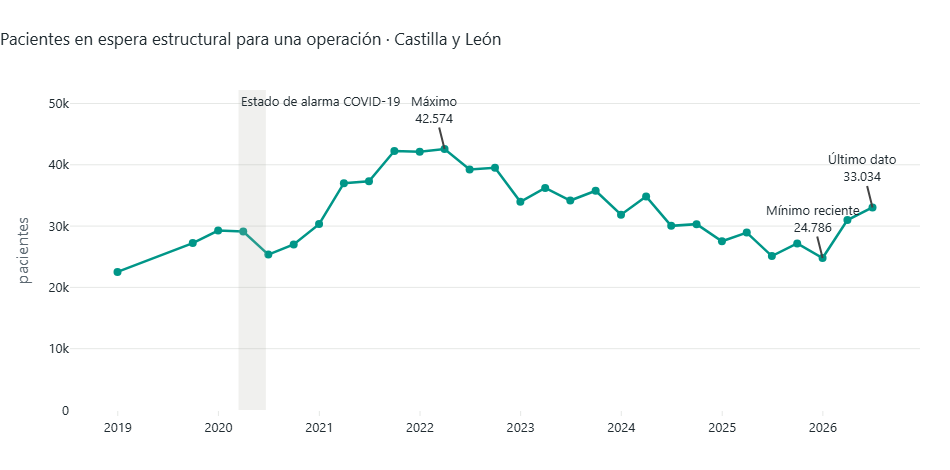

In [4]:
pico = region.loc[region["pacientes_estructurales"].idxmax()]
minimo = region[region["fecha"] > "2023-01-01"].loc[lambda d: d["pacientes_estructurales"].idxmin()]
actual = region.iloc[-1]

fig = go.Figure()
fig.add_scatter(x=region["fecha"], y=region["pacientes_estructurales"], mode="lines+markers",
                name="Pacientes en espera estructural", line_color=PRINCIPAL,
                hovertemplate="%{y:,.0f} pacientes<extra></extra>")
fig.add_vrect(x0="2020-03-14", x1="2020-06-21", fillcolor=CONTEXTO, opacity=0.2, line_width=0,
              annotation_text="Estado de alarma COVID-19", annotation_position="top left")
for punto, texto in [(pico, "Máximo"), (minimo, "Mínimo reciente"), (actual, "Último dato")]:
    fig.add_annotation(x=punto["fecha"], y=punto["pacientes_estructurales"],
                       text=f"{texto}<br>{punto['pacientes_estructurales']:,.0f}".replace(",", "."),
                       showarrow=True, arrowhead=0, ay=-40)
fig.update_layout(title="Pacientes en espera estructural para una operación · Castilla y León",
                  yaxis_title="pacientes", yaxis_rangemode="tozero", showlegend=False,
                  separators=",.")
fig.show()

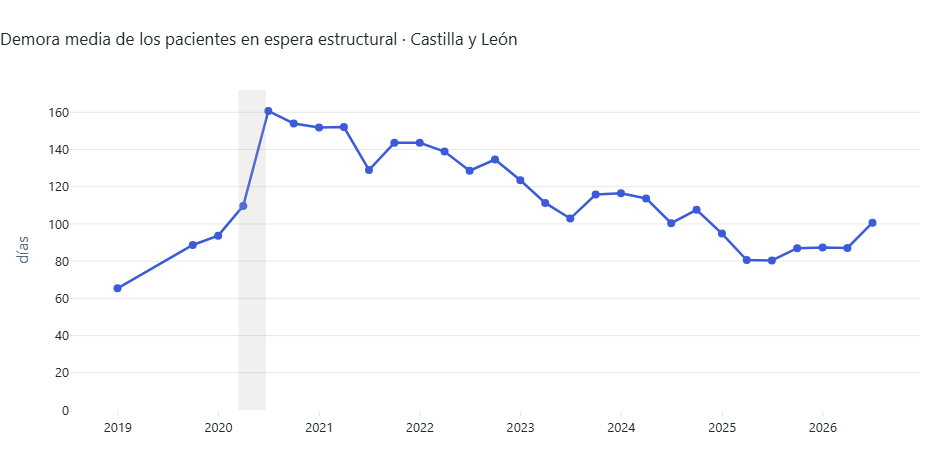

Máximo: 42,574 pacientes (2022-03-31)
Mínimo desde 2023: 24,786 (2025-12-31)
Último dato: 33,034 (2026-06-30), +33 % en seis meses


In [5]:
fig = go.Figure()
fig.add_scatter(x=region["fecha"], y=region["demora_media_dias"], mode="lines+markers",
                line_color=TERCERO, hovertemplate="%{y:.0f} días<extra></extra>")
fig.add_vrect(x0="2020-03-14", x1="2020-06-21", fillcolor=CONTEXTO, opacity=0.2, line_width=0)
fig.update_layout(title="Demora media de los pacientes en espera estructural · Castilla y León",
                  yaxis_title="días", yaxis_rangemode="tozero", showlegend=False, separators=",.")
fig.show()

cambio_semestre = (actual["pacientes_estructurales"] / region.iloc[-3]["pacientes_estructurales"] - 1) * 100
print(f"Máximo: {pico['pacientes_estructurales']:,.0f} pacientes ({pico['fecha'].date()})")
print(f"Mínimo desde 2023: {minimo['pacientes_estructurales']:,.0f} ({minimo['fecha'].date()})")
print(f"Último dato: {actual['pacientes_estructurales']:,.0f} ({actual['fecha'].date()}), "
      f"{cambio_semestre:+.0f} % en seis meses")

**Conclusión**

- La pandemia marcó la serie. Entre septiembre de 2019 y marzo de 2022 la lista estructural pasó de **27.224 a 42.574 pacientes** (+56 %): se aplazaron las operaciones no urgentes y los pacientes se fueron acumulando. La demora media llegó a su máximo, **161 días**, en junio de 2020.
- Desde 2022 la lista bajó de forma sostenida hasta **24.786 pacientes en diciembre de 2025**, por debajo del nivel prepandemia, con una demora de unos 80-87 días durante 2025.
- **En 2026 la tendencia se ha dado la vuelta:** en seis meses la lista subió un 33 %, hasta **33.034 pacientes**, y la demora volvió a superar los 100 días (100,7). Es la señal más importante de los datos recientes.

---
## 2. ¿Cómo está Burgos frente a la media regional y frente a las otras provincias?

Comparar pacientes en bruto no es justo: Valladolid tiene más del triple de habitantes que Soria.
Por eso se usa la **tasa de pacientes en espera estructural por cada 10.000 habitantes**, con la
población del INE de cada trimestre. La calcula la vista SQL `v_quirurgica_provincia`. La tasa
regional se obtiene con el mismo criterio: total de pacientes entre total de habitantes.

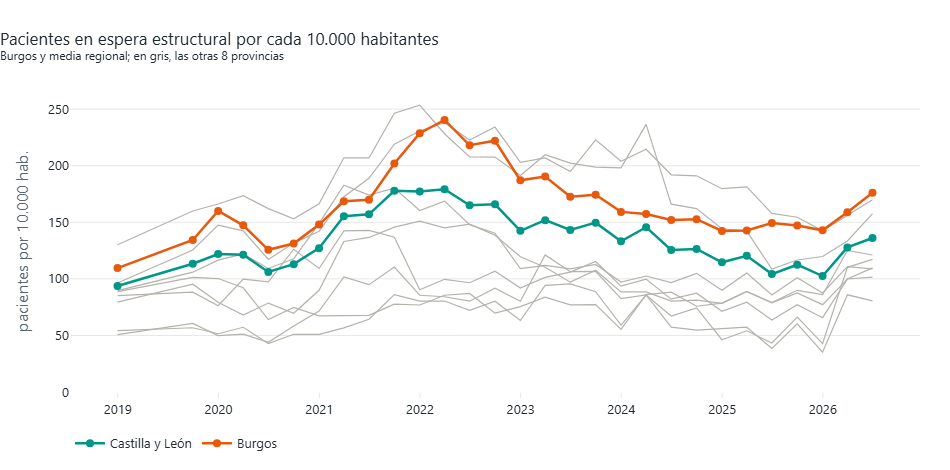

In [6]:
provincias = sql("""
SELECT fecha, provincia, pacientes_estructurales, habitantes,
       estructurales_por_10000_hab AS tasa, demora_media_dias
FROM v_quirurgica_provincia
ORDER BY fecha, provincia
""")

# Tasa regional = suma de pacientes / suma de habitantes de las 9 provincias
tasa_region = (provincias.groupby("fecha")
               .apply(lambda g: g["pacientes_estructurales"].sum() * 10_000 / g["habitantes"].sum(),
                      include_groups=False)
               .rename("tasa").reset_index())

fig = go.Figure()
for nombre, grupo in provincias.groupby("provincia"):
    if nombre == "Burgos":
        continue
    fig.add_scatter(x=grupo["fecha"], y=grupo["tasa"], mode="lines", name=nombre,
                    line=dict(color=CONTEXTO, width=1.2), showlegend=False,
                    hovertemplate=nombre + ": %{y:.0f}<extra></extra>")
fig.add_scatter(x=tasa_region["fecha"], y=tasa_region["tasa"], mode="lines+markers",
                name="Castilla y León", line_color=PRINCIPAL,
                hovertemplate="Castilla y León: %{y:.0f}<extra></extra>")
burgos = provincias[provincias["provincia"] == "Burgos"]
fig.add_scatter(x=burgos["fecha"], y=burgos["tasa"], mode="lines+markers", name="Burgos",
                line_color=DESTACADO, hovertemplate="Burgos: %{y:.0f}<extra></extra>")
fig.update_layout(title="Pacientes en espera estructural por cada 10.000 habitantes<br>"
                        "<sup>Burgos y media regional; en gris, las otras 8 provincias</sup>",
                  yaxis_title="pacientes por 10.000 hab.", yaxis_rangemode="tozero",
                  hovermode="closest")
fig.show()

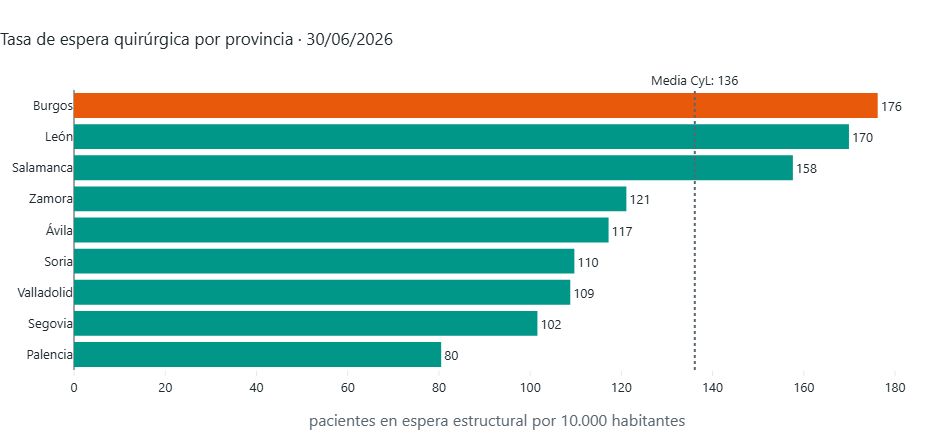

Burgos: 176.2 por 10.000 hab. frente a 136.1 de media (+29 %). Demora: 136 días.


In [7]:
ultimo = provincias[provincias["fecha"] == ULTIMA].sort_values("tasa")
colores = [DESTACADO if p == "Burgos" else PRINCIPAL for p in ultimo["provincia"]]

fig = go.Figure(go.Bar(x=ultimo["tasa"], y=ultimo["provincia"], orientation="h",
                       marker_color=colores, text=ultimo["tasa"].round(0), textposition="outside",
                       hovertemplate="%{y}: %{x:.1f} por 10.000 hab.<extra></extra>"))
valor_region = tasa_region.iloc[-1]["tasa"]
fig.add_vline(x=valor_region, line_dash="dot", line_color="#5b6770",
              annotation_text=f"Media CyL: {valor_region:.0f}", annotation_position="top")
fig.update_layout(title=f"Tasa de espera quirúrgica por provincia · {ULTIMA:%d/%m/%Y}",
                  xaxis_title="pacientes en espera estructural por 10.000 habitantes",
                  hovermode="closest", height=430)
fig.show()

ult_b = ultimo.set_index("provincia").loc["Burgos"]
print(f"Burgos: {ult_b['tasa']:.1f} por 10.000 hab. frente a {valor_region:.1f} de media "
      f"({(ult_b['tasa'] / valor_region - 1) * 100:+.0f} %). Demora: {ult_b['demora_media_dias']:.0f} días.")

In [8]:
# Dentro de la provincia de Burgos: sus tres hospitales
sql(f"""
SELECT hospital, pacientes_estructurales, demora_media_dias
FROM v_quirurgica_hospital
WHERE provincia = 'Burgos' AND fecha = '{ULTIMA:%Y-%m-%d}'
ORDER BY demora_media_dias DESC
""")

,hospital,pacientes_estructurales,demora_media_dias
0,H. Santiago Apóstol,1034,146.6
1,CAU Burgos,4816,137.4
2,H. Santos Reyes,633,105.4


**Conclusión**

- Con el último dato (30/06/2026), **Burgos es la provincia con más espera quirúrgica por habitante: 176 pacientes por cada 10.000 habitantes, un 29 % más que la media regional (136)**. También tiene la demora más alta: 136 días, frente a los 101 de Castilla y León.
- No es algo puntual. Burgos ha estado por encima de la media regional en todos los cortes de la serie. Junto con León y Salamanca, forma el grupo de provincias con más espera, mientras que Palencia (80) y Segovia (102) están en el extremo contrario.
- Dentro de la provincia, el peso lo lleva el **Complejo Asistencial Universitario de Burgos**, con 4.816 pacientes y 137 días. El **Hospital Santiago Apóstol** de Miranda de Ebro tiene la demora más alta de los tres (147 días).

---
## 3. ¿Qué especialidades tienen más espera y cuáles han empeorado más?

Sacyl publica la lista quirúrgica por especialidad solo para el total de la comunidad: no hay
cruce hospital × especialidad. Ese cruce sí existe en consultas externas (sección 6).

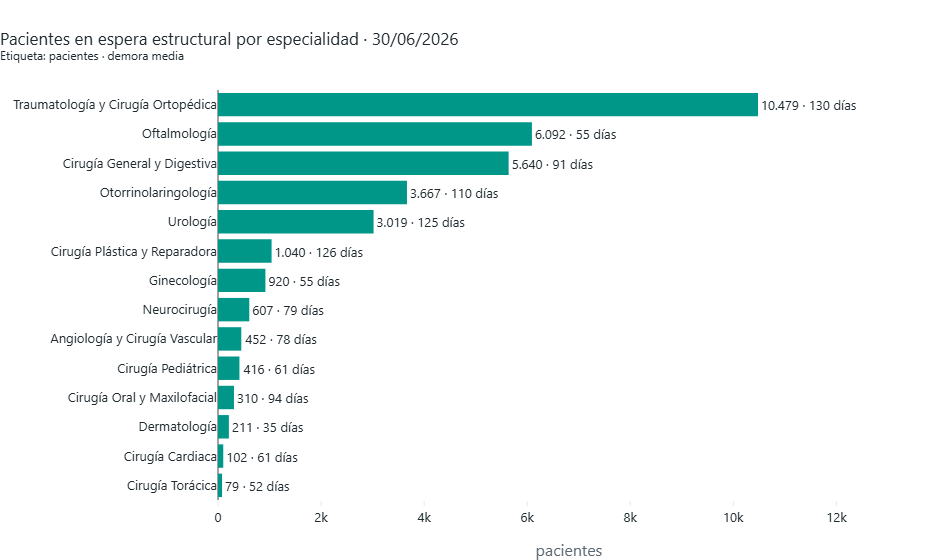

In [9]:
esp = sql("""
SELECT fecha, especialidad, pacientes_estructurales, demora_media_dias
FROM v_quirurgica_especialidad
""")
esp_ult = esp[esp["fecha"] == ULTIMA].sort_values("pacientes_estructurales")
esp_ult["cuota_pct"] = esp_ult["pacientes_estructurales"] / esp_ult["pacientes_estructurales"].sum() * 100

fig = go.Figure(go.Bar(
    x=esp_ult["pacientes_estructurales"], y=esp_ult["especialidad"], orientation="h",
    marker_color=PRINCIPAL,
    customdata=esp_ult[["demora_media_dias", "cuota_pct"]],
    text=[f"{p:,.0f} · {d:.0f} días".replace(",", ".") for p, d in
          zip(esp_ult["pacientes_estructurales"], esp_ult["demora_media_dias"])],
    textposition="outside",
    hovertemplate="%{y}<br>%{x:,.0f} pacientes (%{customdata[1]:.0f} %)<br>"
                  "Demora: %{customdata[0]:.0f} días<extra></extra>"))
fig.update_layout(title=f"Pacientes en espera estructural por especialidad · {ULTIMA:%d/%m/%Y}<br>"
                        "<sup>Etiqueta: pacientes · demora media</sup>",
                  xaxis_title="pacientes", hovermode="closest", height=560,
                  xaxis_range=[0, esp_ult["pacientes_estructurales"].max() * 1.3], separators=",.")
fig.show()

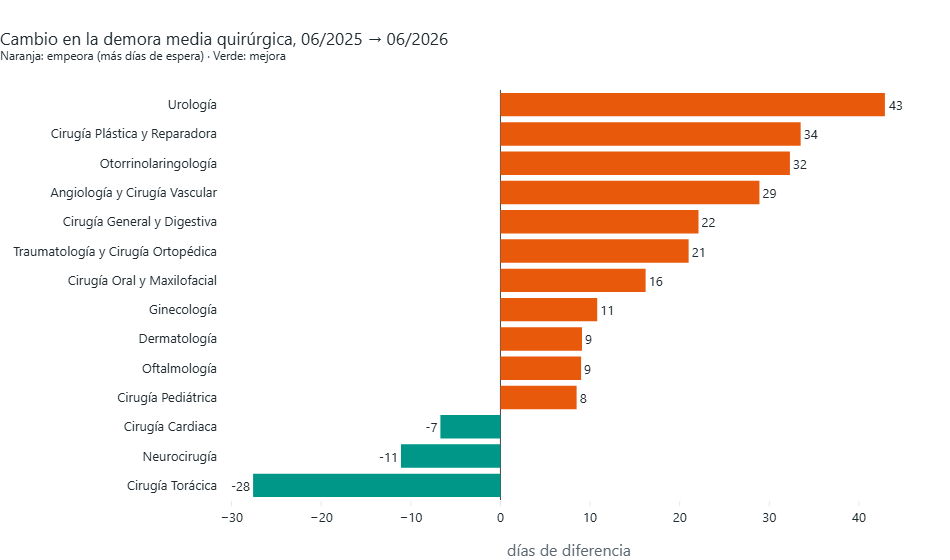

,demora_hace_1_anio,demora_actual,variacion_dias
especialidad,,,
Urología,81.7,124.6,42.9
Cirugía Plástica y Reparadora,92.5,126.0,33.5
Otorrinolaringología,77.9,110.2,32.3
Angiología y Cirugía Vascular,48.6,77.5,28.9
Cirugía General y Digestiva,68.7,90.8,22.1


In [10]:
# ¿Cuáles han empeorado más en el último año? Variación de la demora media en días
hace_un_anio = ULTIMA - pd.DateOffset(years=1)
comparativa = (esp[esp["fecha"].isin([hace_un_anio, ULTIMA])]
               .pivot(index="especialidad", columns="fecha", values="demora_media_dias"))
comparativa.columns = ["demora_hace_1_anio", "demora_actual"]
comparativa["variacion_dias"] = comparativa["demora_actual"] - comparativa["demora_hace_1_anio"]
comparativa = comparativa.sort_values("variacion_dias")

colores = [DESTACADO if v > 0 else PRINCIPAL for v in comparativa["variacion_dias"]]
fig = go.Figure(go.Bar(x=comparativa["variacion_dias"], y=comparativa.index, orientation="h",
                       marker_color=colores, text=comparativa["variacion_dias"].round(0),
                       textposition="outside",
                       hovertemplate="%{y}: %{x:+.1f} días<extra></extra>"))
fig.update_layout(title=f"Cambio en la demora media quirúrgica, {hace_un_anio:%m/%Y} → {ULTIMA:%m/%Y}<br>"
                        "<sup>Naranja: empeora (más días de espera) · Verde: mejora</sup>",
                  xaxis_title="días de diferencia", hovermode="closest", height=560)
fig.show()
comparativa.round(1).sort_values("variacion_dias", ascending=False).head(5)

**Conclusión**

- **Traumatología y Cirugía Ortopédica** concentra casi un tercio de la lista: 10.479 pacientes, el 32 %, con 130 días de demora. Le siguen Oftalmología (6.092 pacientes, aunque con una demora corta, 55 días) y Cirugía General (5.640).
- En el último año la demora ha empeorado en 11 de las 14 especialidades. Los mayores empeoramientos son los de **Urología (+43 días, hasta 125)**, **Cirugía Plástica (+34)**, **Otorrinolaringología (+32)** y **Angiología y Cirugía Vascular (+29)**.
- Otorrinolaringología es además la que más ha empeorado desde 2019 (+40 días y +62 % de pacientes). Neurocirugía y Cirugía Pediátrica tienen hoy menos demora que antes de la pandemia.

---
## 4. ¿Hay estacionalidad? ¿Empeora tras el verano?

Como los datos son trimestrales, se mira **cuánto cambia cada indicador de un corte al
siguiente** según el trimestre. Por ejemplo, el corte de septiembre recoge lo que pasó en
julio, agosto y septiembre. Se excluyen 2019 y 2020 porque la pandemia distorsiona cualquier
patrón.

In [11]:
serie = region.set_index("fecha").copy()
serie["cambio_demora_dias"] = serie["demora_media_dias"].diff()
serie["cambio_pacientes_pct"] = serie["pacientes_estructurales"].pct_change() * 100
# Solo cambios entre trimestres consecutivos (la serie tiene un hueco entre dic-2018 y sep-2019)
consecutivo = serie.index.to_series().diff().dt.days.between(80, 100)
estacional = serie[consecutivo & (serie.index.year >= 2021)].copy()
nombres = {1: "Marzo (ene-mar)", 2: "Junio (abr-jun)", 3: "Septiembre (jul-sep)", 4: "Diciembre (oct-dic)"}
estacional["corte"] = estacional.index.quarter.map(nombres)

resumen = (estacional.groupby("corte", sort=False)
           .agg(cambio_medio_demora=("cambio_demora_dias", "mean"),
                veces_que_sube_la_demora=("cambio_demora_dias", lambda s: f"{(s > 0).sum()} de {len(s)}"),
                cambio_medio_pacientes_pct=("cambio_pacientes_pct", "mean"))
           .reindex(nombres.values()).round(1))
resumen

,cambio_medio_demora,veces_que_sube_la_demora,cambio_medio_pacientes_pct
corte,,,
Marzo (ene-mar),-5.6,1 de 6,11.5
Junio (abr-jun),-6.9,1 de 6,-5.5
Septiembre (jul-sep),9.5,5 de 5,5.6
Diciembre (oct-dic),-4.6,2 de 5,-8.7


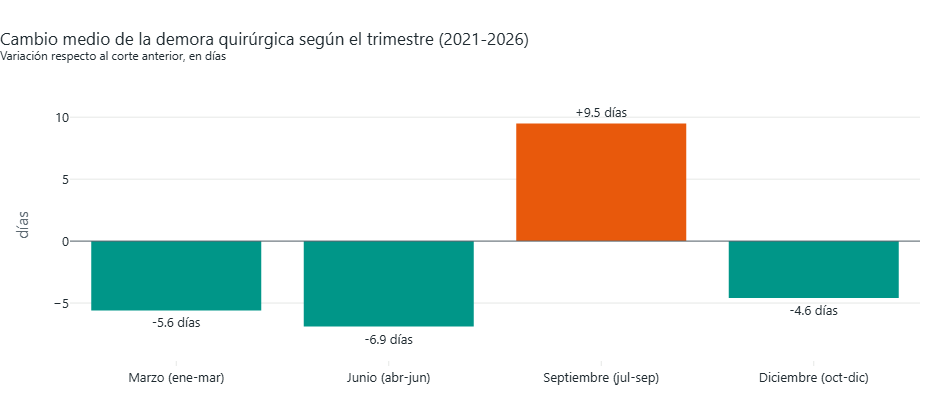

,demora_media_dias,cambio_demora_dias
fecha,,
2021-09-30,143.6,14.6
2022-09-30,134.6,6.0
2023-09-30,115.8,12.9
2024-09-30,107.6,7.2
2025-09-30,87.0,6.6


In [12]:
fig = go.Figure(go.Bar(
    x=resumen.index, y=resumen["cambio_medio_demora"],
    marker_color=[DESTACADO if v > 0 else PRINCIPAL for v in resumen["cambio_medio_demora"]],
    text=[f"{v:+.1f} días" for v in resumen["cambio_medio_demora"]], textposition="outside",
    hovertemplate="%{x}: %{y:+.1f} días de media<extra></extra>"))
fig.update_layout(title="Cambio medio de la demora quirúrgica según el trimestre (2021-2026)<br>"
                        "<sup>Variación respecto al corte anterior, en días</sup>",
                  yaxis_title="días", hovermode="closest", height=420)
fig.add_hline(y=0, line_color="#5b6770", line_width=1)
fig.show()

estacional.loc[estacional.index.quarter == 3, ["demora_media_dias", "cambio_demora_dias"]].round(1)

**Conclusión**

- **Sí, hay un patrón claro tras el verano.** En el corte de septiembre la demora media sube en todos los años analizados (**5 de 5**, de 2021 a 2025), una media de **+9,5 días**. Es el único trimestre en que sube sistemáticamente. Encaja con la menor actividad quirúrgica programada en julio y agosto, por vacaciones y cierre de quirófanos.
- El número de pacientes tiene su propio ritmo: sube en los cortes de marzo y septiembre y baja en los de junio y diciembre. Es compatible con planes de choque de final de semestre, aunque con datos agregados no se puede confirmar la causa.
- Con solo 5-6 años por trimestre el patrón es consistente, pero la muestra es pequeña: conviene tomarlo como indicio fuerte, no como ley.

---
## 5. ¿Qué hospitales destacan para bien o para mal?

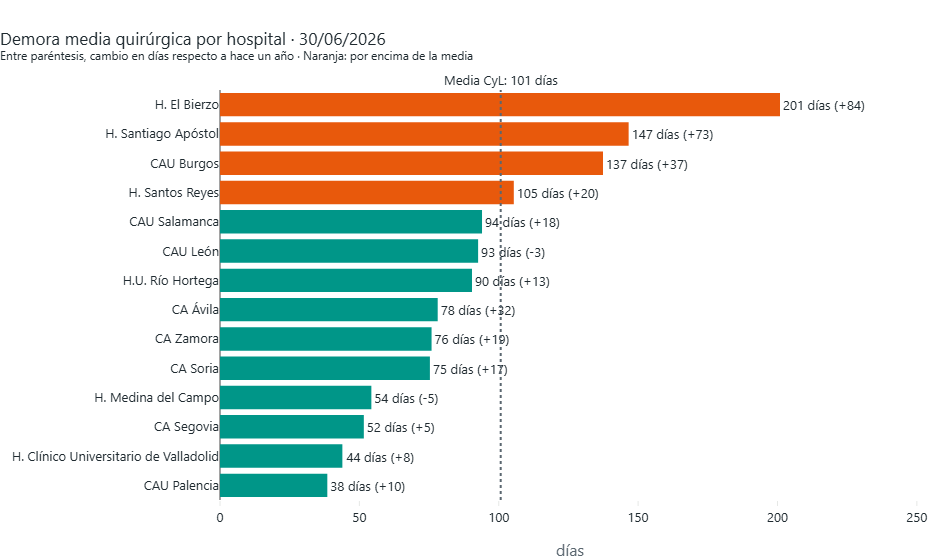

In [13]:
hosp = sql("""
SELECT fecha, hospital, provincia, pacientes_estructurales, demora_media_dias
FROM v_quirurgica_hospital
""")
h_ult = hosp[hosp["fecha"] == ULTIMA].set_index("hospital")
h_ant = hosp[hosp["fecha"] == hace_un_anio].set_index("hospital")
h_ult["variacion_1_anio"] = h_ult["demora_media_dias"] - h_ant["demora_media_dias"]
h_ult = h_ult.sort_values("demora_media_dias")
media_cyl = region.iloc[-1]["demora_media_dias"]

fig = go.Figure(go.Bar(
    x=h_ult["demora_media_dias"], y=h_ult.index, orientation="h",
    marker_color=[DESTACADO if d > media_cyl else PRINCIPAL for d in h_ult["demora_media_dias"]],
    customdata=h_ult[["pacientes_estructurales", "variacion_1_anio"]],
    text=[f"{d:.0f} días ({v:+.0f})" for d, v in zip(h_ult["demora_media_dias"], h_ult["variacion_1_anio"])],
    textposition="outside",
    hovertemplate="%{y}<br>Demora: %{x:.1f} días<br>Pacientes: %{customdata[0]:,.0f}"
                  "<br>Cambio en un año: %{customdata[1]:+.1f} días<extra></extra>"))
fig.add_vline(x=media_cyl, line_dash="dot", line_color="#5b6770",
              annotation_text=f"Media CyL: {media_cyl:.0f} días", annotation_position="top")
fig.update_layout(title=f"Demora media quirúrgica por hospital · {ULTIMA:%d/%m/%Y}<br>"
                        "<sup>Entre paréntesis, cambio en días respecto a hace un año · "
                        "Naranja: por encima de la media</sup>",
                  xaxis_title="días", hovermode="closest", height=560,
                  xaxis_range=[0, h_ult["demora_media_dias"].max() * 1.25])
fig.show()

In [14]:
# Histórico: demora media de cada hospital a lo largo de toda la serie
(hosp.groupby("hospital")["demora_media_dias"]
     .agg(media="mean", minimo="min", maximo="max").round(0)
     .sort_values("media"))

,media,minimo,maximo
hospital,,,
CAU Palencia,49.0,28.0,99.0
CA Ávila,60.0,37.0,99.0
H. Medina del Campo,61.0,40.0,135.0
CA Zamora,67.0,46.0,128.0
CA Segovia,67.0,43.0,110.0
H. Clínico Universitario de Valladolid,76.0,34.0,148.0
H. Santos Reyes,78.0,56.0,105.0
H. Santiago Apóstol,83.0,56.0,147.0
CA Soria,86.0,54.0,141.0


**Conclusión**

- **Para bien:** el **CAU de Palencia** (38 días) y el **Hospital Clínico Universitario de Valladolid** (44) tienen las demoras más bajas de la comunidad. Palencia es además el más estable de toda la serie, con una media histórica de 49 días.
- **Para mal:** el **Hospital El Bierzo** (Ponferrada) tiene la demora más alta, **201 días, 84 más que hace un año**. Le siguen el **Santiago Apóstol** de Miranda de Ebro (147 días, +73) y el **CAU de Burgos** (137, +37). Dos de los tres peores están en la provincia de Burgos.
- En el conjunto de la serie, el CAU de Burgos y el CAU de Salamanca son los que han tenido de forma más constante demoras altas: una media de 150 días cada uno desde 2018.
- Atención: la demora depende también de la complejidad de los casos que atiende cada hospital. Los grandes hospitales de referencia reciben pacientes de otras áreas, así que esto no es un ranking de calidad.

---
## 6. Una mirada a las consultas externas

Antes de operarse, el paciente tiene que pasar por la consulta del especialista. La lista de
**primeras consultas externas** es mucho más grande y aquí sí hay detalle **hospital × especialidad**.

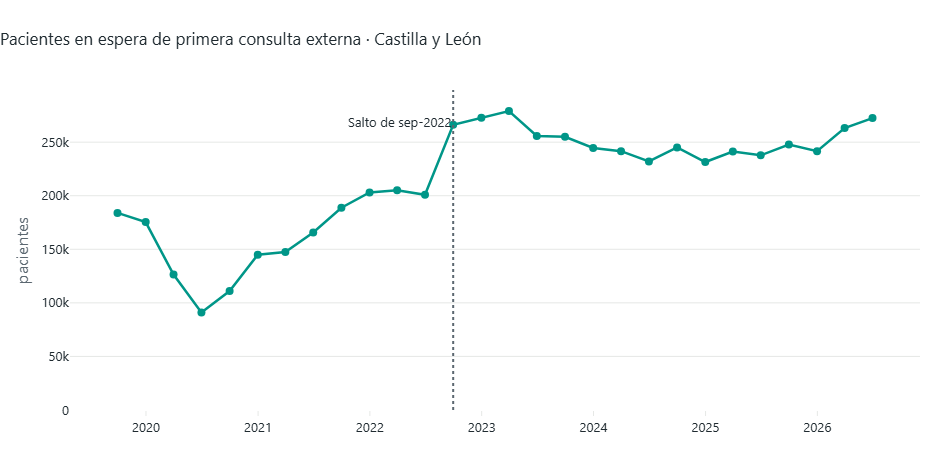

,fecha,pacientes_total,demora_media_dias
24,2025-09-30,247768,100.5
25,2025-12-31,241613,102.1
26,2026-03-31,263111,96.9
27,2026-06-30,272444,104.2


In [15]:
ce = sql("""
SELECT fecha,
       SUM(pacientes_total) AS pacientes_total,
       ROUND(SUM(demora_media_dias * pacientes_estructurales)
             / SUM(CASE WHEN demora_media_dias IS NOT NULL THEN pacientes_estructurales END), 1)
         AS demora_media_dias
FROM consultas_externas
GROUP BY fecha
ORDER BY fecha
""")
fig = go.Figure()
fig.add_scatter(x=ce["fecha"], y=ce["pacientes_total"], mode="lines+markers", line_color=PRINCIPAL,
                hovertemplate="%{y:,.0f} pacientes<extra></extra>")
fig.add_vline(x="2022-09-30", line_dash="dot", line_color="#5b6770")
fig.add_annotation(x="2022-09-30", y=ce["pacientes_total"].max(), text="Salto de sep-2022",
                   showarrow=False, xanchor="right", yanchor="top")
fig.update_layout(title="Pacientes en espera de primera consulta externa · Castilla y León",
                  yaxis_title="pacientes", yaxis_rangemode="tozero", showlegend=False, separators=",.")
fig.show()
ce.tail(4)

In [16]:
# Ejemplo de pregunta concreta: traumatología en los hospitales de Burgos
sql(f"""
SELECT hospital, pacientes_total, demora_media_dias
FROM v_consultas_detalle
WHERE provincia = 'Burgos'
  AND especialidad = 'Traumatología y Cirugía Ortopédica'
  AND fecha = '{ULTIMA:%Y-%m-%d}'
ORDER BY demora_media_dias DESC
""")

,hospital,pacientes_total,demora_media_dias
0,CAU Burgos,5711,144.0
1,H. Santos Reyes,2259,134.9
2,H. Santiago Apóstol,1744,113.5


**Conclusión**

- La lista de consultas externas (**272.444 pacientes en junio de 2026**) es unas seis veces la quirúrgica. Está en su nivel más alto desde marzo de 2023, con una demora media ponderada de **104 días**, la mayor desde la pandemia (en junio de 2020 llegó a 127).
- Entre junio y septiembre de 2022 la lista salta de 200.875 a 266.269 pacientes (+33 %) en un solo trimestre. Un salto tan brusco apunta más a un **cambio en cómo se registra la lista** que a un cambio real, así que no conviene comparar directamente las cifras de antes y de después.
- En la provincia de Burgos, la primera consulta de Traumatología tiene una demora de 144 días en el CAU de Burgos, 135 en el Santos Reyes y 114 en el Santiago Apóstol.

---
## 7. Previsión a 12 meses

El módulo `src/prevision.py` compara, para la comunidad y para cada provincia, tres modelos de
referencia muy simples con un modelo de suavizado exponencial (ETS / Holt-Winters):

- **Último valor:** el próximo trimestre será igual que el último.
- **Estacional ingenuo:** igual que el mismo trimestre del año anterior.
- **Media móvil de 4 trimestres.**
- **ETS** con tendencia amortiguada y estacionalidad trimestral.

Se entrenan con los datos hasta junio de 2025, se prueban con los 4 trimestres siguientes, se
mide el error (MAE en pacientes y MAPE en %) y se elige el modelo con menor MAE.

In [17]:
evaluacion = sql("SELECT * FROM prevision_evaluacion")
tabla_mape = evaluacion.pivot(index="ambito", columns="modelo", values="mape").round(1)
tabla_mape["modelo_elegido"] = evaluacion[evaluacion["elegido"] == 1].set_index("ambito")["modelo"]
tabla_mape

modelo,estacional_ingenuo,ets_holt_winters,media_movil_4,ultimo_valor,modelo_elegido
ambito,,,,,
Burgos,7.8,4.7,7.2,6.9,ets_holt_winters
Castilla y León,13.3,20.6,10.2,13.0,media_movil_4
León,18.0,10.9,13.9,5.1,ultimo_valor
Palencia,38.6,36.6,34.4,38.3,media_movil_4
Salamanca,23.8,12.4,12.6,16.9,media_movil_4
Segovia,11.1,15.4,13.0,14.3,estacional_ingenuo
Soria,20.9,34.2,18.3,24.9,media_movil_4
Valladolid,8.2,14.7,10.3,15.7,estacional_ingenuo
Zamora,22.0,25.9,21.4,22.9,estacional_ingenuo


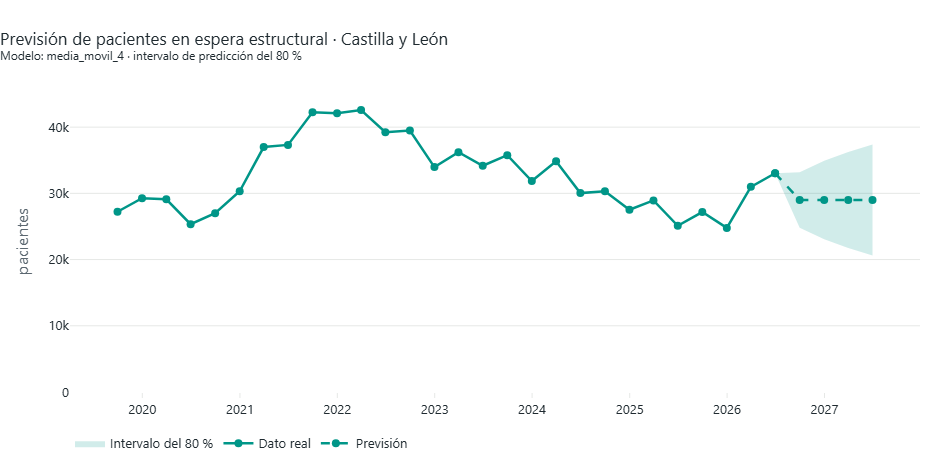

,fecha,prevision,inferior,superior
0,2026-09-30,28996.0,24805.0,33187.0
1,2026-12-31,28996.0,23069.0,34923.0
2,2027-03-31,28996.0,21737.0,36255.0
3,2027-06-30,28996.0,20614.0,37378.0


In [18]:
prev = sql("SELECT * FROM prevision WHERE ambito = 'Castilla y León'")
historico = region[region["fecha"] >= "2019-09-30"]
# Para que la línea de la previsión parta del último dato real
enlace = pd.DataFrame({"fecha": [historico["fecha"].iloc[-1]],
                       "prevision": [historico["pacientes_estructurales"].iloc[-1]],
                       "inferior": [historico["pacientes_estructurales"].iloc[-1]],
                       "superior": [historico["pacientes_estructurales"].iloc[-1]]})
prev_g = pd.concat([enlace, prev[["fecha", "prevision", "inferior", "superior"]]])

fig = go.Figure()
fig.add_scatter(x=list(prev_g["fecha"]) + list(prev_g["fecha"][::-1]),
                y=list(prev_g["superior"]) + list(prev_g["inferior"][::-1]),
                mode="lines", fill="toself", fillcolor=estilo.INTERVALO, line_width=0, hoverinfo="skip",
                name="Intervalo del 80 %")
fig.add_scatter(x=historico["fecha"], y=historico["pacientes_estructurales"], mode="lines+markers",
                name="Dato real", line_color=PRINCIPAL, hovertemplate="%{y:,.0f}<extra></extra>")
fig.add_scatter(x=prev_g["fecha"], y=prev_g["prevision"], mode="lines+markers", name="Previsión",
                line=dict(color=PRINCIPAL, dash="dash"), hovertemplate="%{y:,.0f}<extra></extra>")
fig.update_layout(title="Previsión de pacientes en espera estructural · Castilla y León<br>"
                        f"<sup>Modelo: {prev['modelo'].iloc[0]} · intervalo de predicción del 80 %</sup>",
                  yaxis_title="pacientes", yaxis_rangemode="tozero", separators=",.")
fig.show()
prev[["fecha", "prevision", "inferior", "superior"]]

**Conclusión y limitaciones de la previsión**

- **El modelo "sofisticado" solo gana en una de las 10 series.** El ETS es el mejor en Burgos (error del 4,7 %), pero en Castilla y León gana la **media móvil de 4 trimestres** (10,2 %, frente al 20,6 % del ETS). En el resto de provincias ganan también modelos simples. Con unos 24 trimestres de entrenamiento, y en plena distorsión por la pandemia, un modelo con tendencia y estacionalidad tiene poco de donde aprender.
- Para la comunidad, el modelo elegido prevé unos **29.000 pacientes** en los próximos trimestres, con un intervalo del 80 % que se ensancha de 24.800-33.200 a 20.600-37.400. La media móvil va por detrás de los cambios bruscos: el salto de 2026 todavía no lo ha incorporado del todo. **Si la subida continúa, el valor real quedará en la parte alta del intervalo.**
- El conjunto de prueba son solo 4 puntos, así que la elección del modelo es frágil. Una evaluación más robusta usaría validación con origen móvil (*rolling origin*).
- Ningún modelo sabe nada de lo que mueve de verdad la lista: planes de choque, contratación de cirujanos, huelgas o derivaciones a la privada. Esto es una **extrapolación estadística**, útil como referencia, no una predicción de lo que va a pasar.

---
## Hallazgos principales

1. **La lista de espera quirúrgica vuelve a crecer.** Tras bajar de 42.574 pacientes estructurales (marzo de 2022) a 24.786 (diciembre de 2025), en el primer semestre de 2026 ha subido un 33 %, hasta 33.034, y la demora ha vuelto a los 101 días.
2. **Burgos es la provincia con más espera por habitante:** 176 pacientes por 10.000 habitantes, un 29 % por encima de la media, y la mayor demora provincial (136 días). Dos de los tres hospitales con más demora son burgaleses.
3. **El Hospital El Bierzo tiene la mayor demora (201 días) y la que más ha empeorado (+84 días en un año).** En el lado bueno están el CAU de Palencia (38 días) y el Clínico de Valladolid (44).
4. **Traumatología concentra el 32 % de la lista**, y **Urología es la especialidad que más ha empeorado en el último año** (+43 días).
5. **La demora sube siempre tras el verano:** en 5 de 5 años, el corte de septiembre muestra más demora que el de junio (+9,5 días de media).

## Limitaciones de los datos

- **Datos agregados y trimestrales:** son fotos del último día del trimestre, sin datos por paciente. No se ven entradas ni salidas de la lista, solo el saldo.
- **Sin cruce hospital × especialidad en la lista quirúrgica:** Sacyl solo lo publica para consultas externas.
- **Hueco al inicio de la serie:** marzo y junio de 2019 no están en Excel (junio solo en PDF), así que la serie continua empieza en septiembre de 2019, con un dato suelto de diciembre de 2018.
- **Posible cambio de registro en consultas externas** en septiembre de 2022 (+33 % en un trimestre).
- **Demora media, no mediana:** unos pocos pacientes con esperas muy largas pueden subir la media.
- **La demora no es calidad:** depende de la complejidad de los casos y de la población de referencia de cada hospital, que en los de referencia incluye pacientes de otras áreas.
- **Población:** en 2019-2020 el INE da cifras semestrales; para cada corte se usa la cifra más reciente disponible.